# ADHD multi-class (Control / ADHD-Combined / ADHD-Inattentive) — balancing, model selection, tuning, explainability

Target `DX`: **0 = Control, 1 = ADHD-Combined, 2 = ADHD-Inattentive**. Input file: `adhd_cleaned_multiclass.csv` from `cleaning_multiclass.ipynb`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path

import dice_ml
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.over_sampling import ADASYN, SMOTE, BorderlineSMOTE, RandomOverSampler, SVMSMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from mealpy import GA, GWO, PSO, WOA, FloatVar
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             balanced_accuracy_score, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEED = 42
N_JOBS = -1
SELECT = 'f1'                # macro-F1; metric used to pick the best balancer/model/tuner
MODEL_DIR = Path('models'); MODEL_DIR.mkdir(exist_ok=True)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')

## 1. Data

`ADHD_Index`, `Inattentive` and `Hyper_Impulsive` are the rating scales that clinicians use when diagnosing ADHD, so they are very strong (near-diagnostic) predictors. To test how well the model works from IQ / demographic information alone, list them in `EXCLUDE` below and re-run; the counterfactual section adapts automatically.

In [2]:
df = pd.read_csv('adhd_cleaned_multiclass.csv')
df.columns = df.columns.str.replace(r'[ /]', '_', regex=True)

TARGET = 'DX'
assert set(df[TARGET].unique()) == {0, 1, 2}, 'DX must be 0/1/2: use adhd_cleaned_multiclass.csv'

EXCLUDE = []                 # e.g. ['ADHD_Index', 'Inattentive', 'Hyper_Impulsive']
FEATURES = [c for c in df.columns if c != TARGET and c not in EXCLUDE]
CAT = [c for c in ['Gender', 'Handedness', 'ADHD_Measure', 'IQ_Measure'] if c in FEATURES]   # coded categories
NUM = [c for c in FEATURES if c not in CAT]
CLASSES = [0, 1, 2]
CLASS_NAMES = ['Control', 'ADHD-Combined', 'ADHD-Inattentive']
N_CLASSES = len(CLASSES)

print('shape:', df.shape, '| missing:', df.isna().sum().sum(), '| duplicates:', df.duplicated().sum())
print('DX counts:', df[TARGET].value_counts().sort_index().to_dict())
print('categorical:', CAT)
print('numeric    :', NUM)
df[FEATURES + [TARGET]].describe().T

shape: (505, 12) | missing: 0 | duplicates: 0
DX counts: {0: 271, 1: 130, 2: 104}
categorical: ['Gender', 'Handedness', 'ADHD_Measure', 'IQ_Measure']
numeric    : ['Age', 'ADHD_Index', 'Inattentive', 'Hyper_Impulsive', 'Verbal_IQ', 'Performance_IQ', 'Full4_IQ']


,count,mean,std,min,25%,50%,75%,max
Gender,505.0,0.663366,0.473027,0.00,0.0,1.00,1.0,1.00
Age,505.0,11.350436,2.349518,7.17,9.5,11.09,13.0,17.96
Handedness,505.0,0.976238,0.176579,0.00,1.0,1.00,1.0,2.00
ADHD_Measure,505.0,1.562376,0.496586,1.00,1.0,2.00,2.0,2.00
ADHD_Index,505.0,49.529703,17.157970,18.00,40.0,46.00,62.0,99.00
Inattentive,505.0,41.761386,21.948872,9.00,23.0,42.00,59.0,90.00
Hyper_Impulsive,505.0,40.000000,23.052971,9.00,17.0,43.00,56.0,90.00
IQ_Measure,505.0,2.279208,0.720493,1.00,2.0,2.00,3.0,3.00
Verbal_IQ,505.0,112.655446,15.068893,65.00,102.0,112.00,123.0,158.00
Performance_IQ,505.0,105.912871,14.596434,54.00,96.0,106.00,117.0,139.00


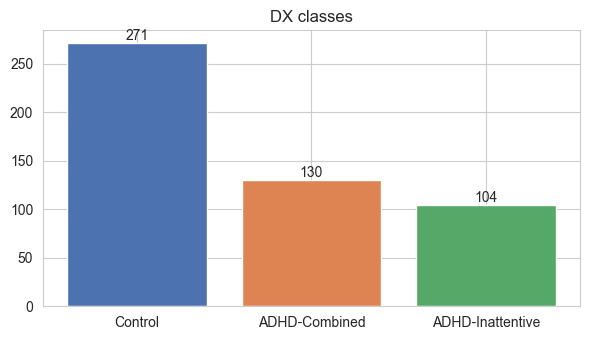

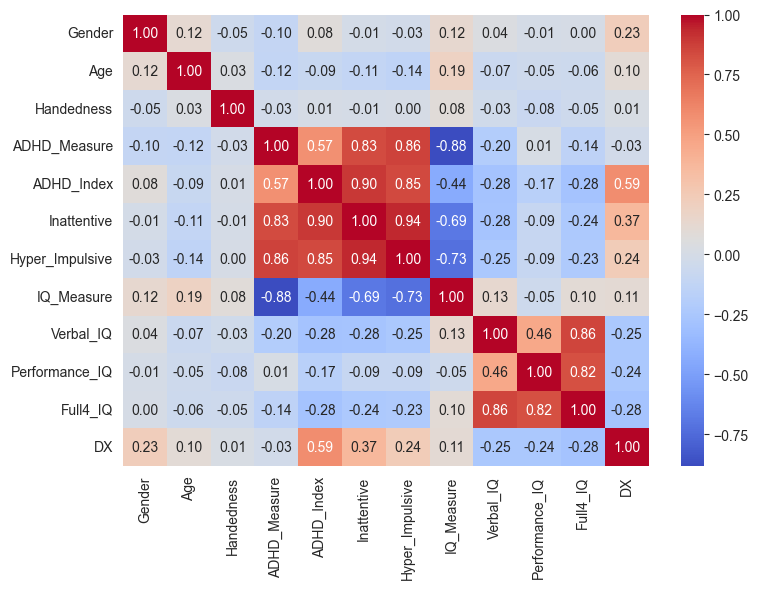

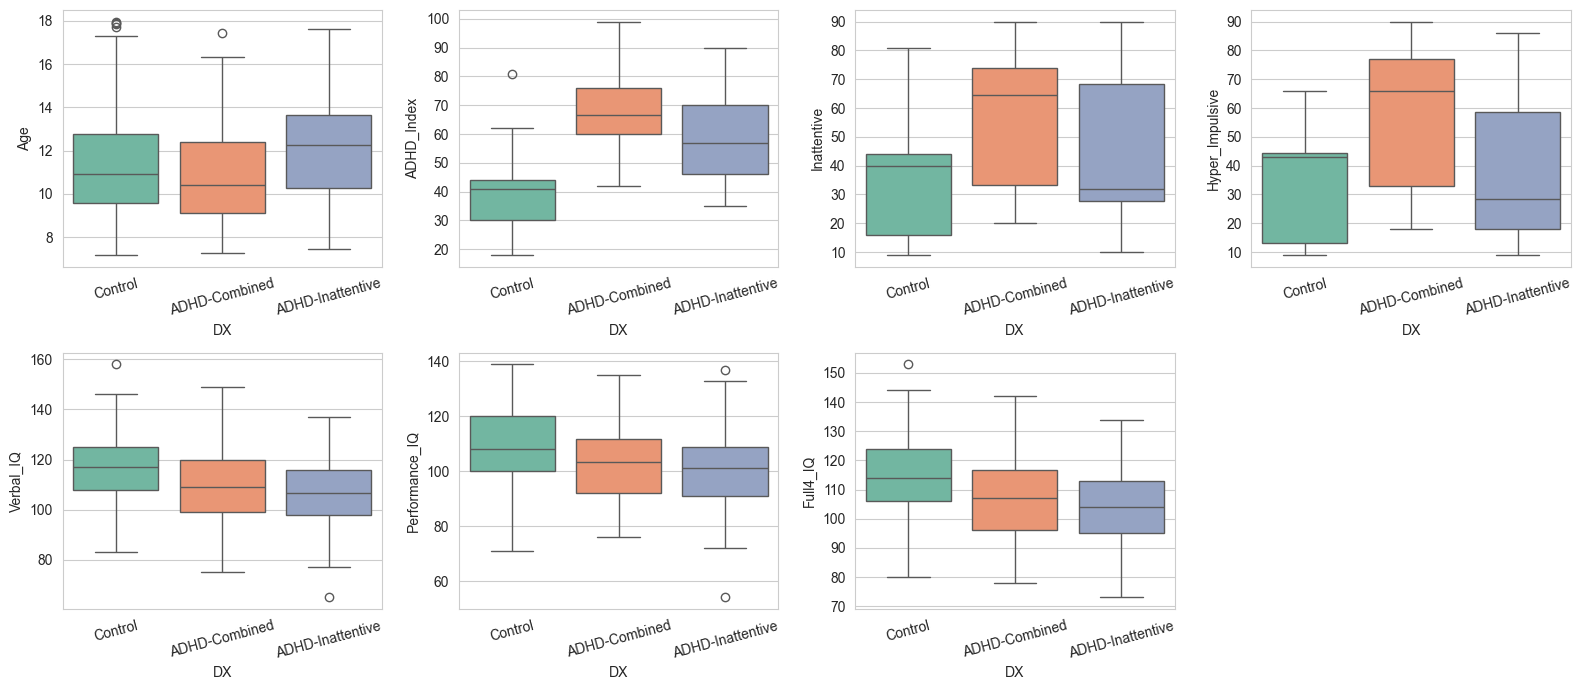

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
counts = df[TARGET].value_counts().sort_index()
ax.bar(CLASS_NAMES, counts.values, color=['#4C72B0', '#DD8452', '#55A868'])
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_title('DX classes')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
plt.tight_layout(); plt.show()

ncols = 4
nrows = int(np.ceil(len(NUM) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.5 * nrows))
for ax, col in zip(axes.flat, NUM):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette='Set2', legend=False, ax=ax)
    ax.set_xticks(CLASSES); ax.set_xticklabels(CLASS_NAMES, rotation=15)
for ax in axes.flat[len(NUM):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Train / test split

In [4]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print('train:', X_train.shape, y_train.value_counts().sort_index().to_dict())
print('test :', X_test.shape, y_test.value_counts().sort_index().to_dict())

train: (378, 11) {0: 203, 1: 97, 2: 78}
test : (127, 11) {0: 68, 1: 33, 2: 26}


## 3. Pipeline: preprocessing → balancer → model

Balancing runs inside every CV fold (imblearn `Pipeline`), so synthetic samples never leak into validation data. Precision / recall / F1 are **macro-averaged** (every class counts equally, so the smaller ADHD subtypes are not drowned out by Control); ROC AUC is one-vs-rest macro. Macro-F1 is the selection metric.

In [5]:
BALANCERS = {
    'None': None,
    'RandomOver': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED),
    'BorderlineSMOTE': BorderlineSMOTE(random_state=SEED),
    'SVMSMOTE': SVMSMOTE(random_state=SEED),
    'ADASYN': ADASYN(random_state=SEED),
    'SMOTETomek': SMOTETomek(random_state=SEED),
    'SMOTEENN': SMOTEENN(random_state=SEED),
    'RandomUnder': RandomUnderSampler(random_state=SEED),
}

MODELS = {
    'LogReg': LogisticRegression(max_iter=2000, random_state=SEED),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(probability=True, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
    'XGBoost': xgb.XGBClassifier(objective='multi:softprob', num_class=N_CLASSES, eval_metric='mlogloss',
                                 random_state=SEED, n_jobs=1, verbosity=0),
}

METRICS = {
    'accuracy': 'accuracy',
    'balanced_acc': 'balanced_accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro',
    'roc_auc': 'roc_auc_ovr',
}
CV_EVAL = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)


def build(model, balancer):
    prep = ColumnTransformer([
        ('num', StandardScaler(), NUM),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
    ])
    sampler = clone(balancer) if balancer is not None else 'passthrough'
    return Pipeline([('prep', prep), ('sampler', sampler), ('clf', clone(model))])


def cv_eval(pipe):
    res = cross_validate(pipe, X_train, y_train, cv=CV_EVAL, scoring=METRICS,
                         n_jobs=N_JOBS, error_score=np.nan)
    return {k: res[f'test_{k}'].mean() for k in METRICS}


def test_eval(pipe):
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)
    return {
        'accuracy': accuracy_score(y_test, pred),
        'balanced_acc': balanced_accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'f1': f1_score(y_test, pred, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y_test, proba, multi_class='ovr', average='macro', labels=pipe.classes_),
    }

## 4. Balancing approach × model (repeated stratified CV on train)

In [6]:
rows = []
for m_name, model in MODELS.items():
    for b_name, balancer in BALANCERS.items():
        t0 = time.time()
        scores = cv_eval(build(model, balancer))
        rows.append({'model': m_name, 'balancer': b_name, **scores, 'sec': time.time() - t0})
        print(f"{m_name:13s} {b_name:16s} {SELECT}={scores[SELECT]:.3f}")

grid = pd.DataFrame(rows).sort_values(SELECT, ascending=False).reset_index(drop=True)
grid.head(10).round(3)

LogReg        None             f1=0.787
LogReg        RandomOver       f1=0.790
LogReg        SMOTE            f1=0.793
LogReg        BorderlineSMOTE  f1=0.791
LogReg        SVMSMOTE         f1=0.786
LogReg        ADASYN           f1=0.789
LogReg        SMOTETomek       f1=0.793
LogReg        SMOTEENN         f1=0.792
LogReg        RandomUnder      f1=0.788
KNN           None             f1=0.680
KNN           RandomOver       f1=0.672
KNN           SMOTE            f1=0.678
KNN           BorderlineSMOTE  f1=0.681
KNN           SVMSMOTE         f1=0.691
KNN           ADASYN           f1=0.676
KNN           SMOTETomek       f1=0.682
KNN           SMOTEENN         f1=0.671
KNN           RandomUnder      f1=0.672
SVM           None             f1=0.718
SVM           RandomOver       f1=0.739
SVM           SMOTE            f1=0.755
SVM           BorderlineSMOTE  f1=0.737
SVM           SVMSMOTE         f1=0.736
SVM           ADASYN           f1=0.768
SVM           SMOTETomek       f1=0.750


,model,balancer,accuracy,balanced_acc,precision,recall,f1,roc_auc,sec
0,LogReg,SMOTE,0.847,0.796,0.796,0.796,0.793,0.947,0.290
1,LogReg,SMOTETomek,0.847,0.796,0.796,0.796,0.793,0.947,0.090
2,LogReg,SMOTEENN,0.845,0.797,0.794,0.797,0.792,0.939,0.131
3,LogReg,BorderlineSMOTE,0.846,0.794,0.795,0.794,0.791,0.945,0.133
4,LogReg,RandomOver,0.841,0.795,0.791,0.795,0.790,0.947,0.197
5,LogReg,ADASYN,0.841,0.793,0.792,0.793,0.789,0.949,0.098
6,LogReg,RandomUnder,0.840,0.793,0.790,0.793,0.788,0.948,0.087
7,LogReg,None,0.847,0.785,0.799,0.785,0.787,0.949,3.690
8,LogReg,SVMSMOTE,0.841,0.789,0.790,0.789,0.786,0.944,0.129
9,RandomForest,RandomUnder,0.840,0.788,0.786,0.788,0.784,0.939,1.400


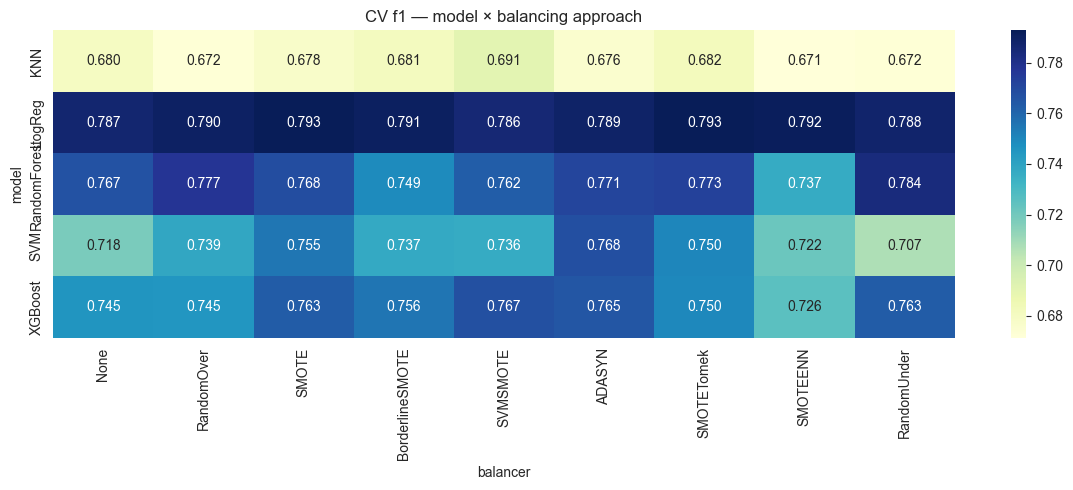

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(grid.pivot(index='model', columns='balancer', values=SELECT)[list(BALANCERS)],
            annot=True, fmt='.3f', cmap='YlGnBu', ax=ax)
ax.set_title(f'CV {SELECT} — model × balancing approach')
plt.tight_layout(); plt.show()

## 5. Best model + balancer (stored)

In [8]:
best = grid.iloc[0]
BEST_MODEL, BEST_BALANCER = best['model'], best['balancer']
print(f'WINNER: {BEST_MODEL} + {BEST_BALANCER} | CV {SELECT} = {best[SELECT]:.3f}')


def build_best(params=None):
    model = clone(MODELS[BEST_MODEL]).set_params(**(params or {}))
    return build(model, BALANCERS[BEST_BALANCER])


best_pipe = build_best().fit(X_train, y_train)
joblib.dump({'pipeline': best_pipe, 'model': BEST_MODEL, 'balancer': BEST_BALANCER,
             'features': FEATURES, 'cv_scores': best[list(METRICS)].to_dict()},
            MODEL_DIR / 'best_base_model_multiclass.joblib')
pd.Series(test_eval(best_pipe), name='holdout test').round(3)

WINNER: LogReg + SMOTE | CV f1 = 0.793


accuracy        0.866
balanced_acc    0.833
precision       0.821
recall          0.833
f1              0.826
roc_auc         0.947
Name: holdout test, dtype: float64

## 6. Tuning the winner: GWO, GA, PSO, WOA, Optuna

All optimizers search the same space with the same evaluation budget; fitness = 5-fold CV score on train.

In [9]:
SPACES = {
    'LogReg': [('C', 'float', 1e-3, 100, True)],
    'KNN': [('n_neighbors', 'int', 3, 25, False), ('p', 'int', 1, 2, False)],
    'SVM': [('C', 'float', 1e-2, 100, True), ('gamma', 'float', 1e-4, 1, True)],
    'RandomForest': [
        ('n_estimators', 'int', 100, 600, False),
        ('max_depth', 'int', 2, 20, False),
        ('min_samples_split', 'int', 2, 20, False),
        ('min_samples_leaf', 'int', 1, 10, False),
        ('max_features', 'float', 0.3, 1.0, False),
    ],
    'XGBoost': [
        ('n_estimators', 'int', 50, 400, False),
        ('learning_rate', 'float', 0.01, 0.3, True),
        ('max_depth', 'int', 2, 8, False),
        ('subsample', 'float', 0.5, 1.0, False),
        ('colsample_bytree', 'float', 0.4, 1.0, False),
        ('min_child_weight', 'int', 1, 10, False),
    ],
}
SPACE = SPACES[BEST_MODEL]

POP, EPOCH = 20, 15
N_EVALS = POP * (EPOCH + 1)
CV_TUNE = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
TUNE_SCORING = METRICS[SELECT]


def decode(vec):
    params = {}
    for u, (name, kind, lo, hi, log) in zip(vec, SPACE):
        v = np.exp(np.log(lo) + u * (np.log(hi) - np.log(lo))) if log else lo + u * (hi - lo)
        params[name] = int(round(v)) if kind == 'int' else float(v)
    return params


def fitness(vec):
    return cross_val_score(build_best(decode(vec)), X_train, y_train, cv=CV_TUNE,
                           scoring=TUNE_SCORING, n_jobs=N_JOBS, error_score=0.0).mean()


MEALPY = {
    'GWO': lambda: GWO.OriginalGWO(epoch=EPOCH, pop_size=POP),
    'GA': lambda: GA.BaseGA(epoch=EPOCH, pop_size=POP),
    'PSO': lambda: PSO.OriginalPSO(epoch=EPOCH, pop_size=POP),
    'WOA': lambda: WOA.OriginalWOA(epoch=EPOCH, pop_size=POP),
}
problem = {'obj_func': fitness, 'bounds': FloatVar(lb=[0.0] * len(SPACE), ub=[1.0] * len(SPACE)),
           'minmax': 'max', 'log_to': None}

tuning = []
for name, make in MEALPY.items():
    t0 = time.time()
    opt = make()
    sol = opt.solve(problem, seed=SEED)
    tuning.append({'optimizer': name, 'cv_tune': sol.target.fitness, 'params': decode(sol.solution),
                   'sec': time.time() - t0,
                   'curve': (np.arange(len(opt.history.list_global_best_fit)) + 1) * POP,
                   'best_so_far': list(opt.history.list_global_best_fit)})
    print(f"{name:7s} CV {TUNE_SCORING}={sol.target.fitness:.4f} | {time.time() - t0:.0f}s | {decode(sol.solution)}")

t0 = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(lambda trial: fitness([trial.suggest_float(s[0], 0, 1) for s in SPACE]), n_trials=N_EVALS)
tuning.append({'optimizer': 'Optuna', 'cv_tune': study.best_value,
               'params': decode([study.best_params[s[0]] for s in SPACE]), 'sec': time.time() - t0,
               'curve': np.arange(1, N_EVALS + 1),
               'best_so_far': list(np.maximum.accumulate([t.value for t in study.trials]))})
print(f"{'Optuna':7s} CV {TUNE_SCORING}={study.best_value:.4f} | {time.time() - t0:.0f}s | {tuning[-1]['params']}")

GWO     CV f1_macro=0.8020 | 11s | {'C': 6.008992623205475}
GA      CV f1_macro=0.8020 | 11s | {'C': 8.517684046357212}
PSO     CV f1_macro=0.8020 | 11s | {'C': 11.846361360711906}
WOA     CV f1_macro=0.8039 | 10s | {'C': 0.2960455664232155}
Optuna  CV f1_macro=0.8039 | 11s | {'C': 0.2970353693972879}


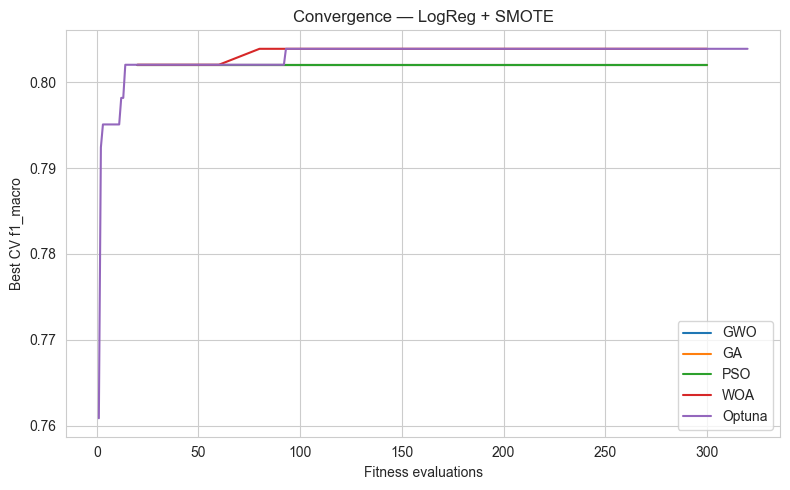

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for r in tuning:
    ax.plot(r['curve'], r['best_so_far'], label=r['optimizer'])
ax.set_xlabel('Fitness evaluations'); ax.set_ylabel(f'Best CV {TUNE_SCORING}')
ax.set_title(f'Convergence — {BEST_MODEL} + {BEST_BALANCER}')
ax.legend()
plt.tight_layout(); plt.show()

## 7. Final comparison

Ranked by repeated-CV score (different folds than tuning). Holdout test columns are the unbiased check.

In [11]:
final_pipes = {f'{BEST_MODEL}+{BEST_BALANCER} (default)': build_best()}
final_pipes.update({f"{BEST_MODEL}+{BEST_BALANCER} + {r['optimizer']}": build_best(r['params']) for r in tuning})

rows = {}
for name, pipe in final_pipes.items():
    pipe.fit(X_train, y_train)
    rows[name] = {f'cv_{SELECT}': cv_eval(pipe)[SELECT],
                  **{f'test_{k}': v for k, v in test_eval(pipe).items()}}
final_df = pd.DataFrame(rows).T.sort_values(f'cv_{SELECT}', ascending=False)

winner_name = final_df.index[0]
winner_pipe = final_pipes[winner_name]
print('FINAL WINNER:', winner_name)
final_df.round(3)

FINAL WINNER: LogReg+SMOTE + WOA


,cv_f1,test_accuracy,test_balanced_acc,test_precision,test_recall,test_f1,test_roc_auc
LogReg+SMOTE + WOA,0.804,0.866,0.833,0.821,0.833,0.826,0.949
LogReg+SMOTE + Optuna,0.804,0.866,0.833,0.821,0.833,0.826,0.949
LogReg+SMOTE (default),0.793,0.866,0.833,0.821,0.833,0.826,0.947
LogReg+SMOTE + GA,0.792,0.874,0.846,0.838,0.846,0.839,0.947
LogReg+SMOTE + GWO,0.792,0.874,0.846,0.838,0.846,0.839,0.947
LogReg+SMOTE + PSO,0.790,0.874,0.846,0.838,0.846,0.839,0.947


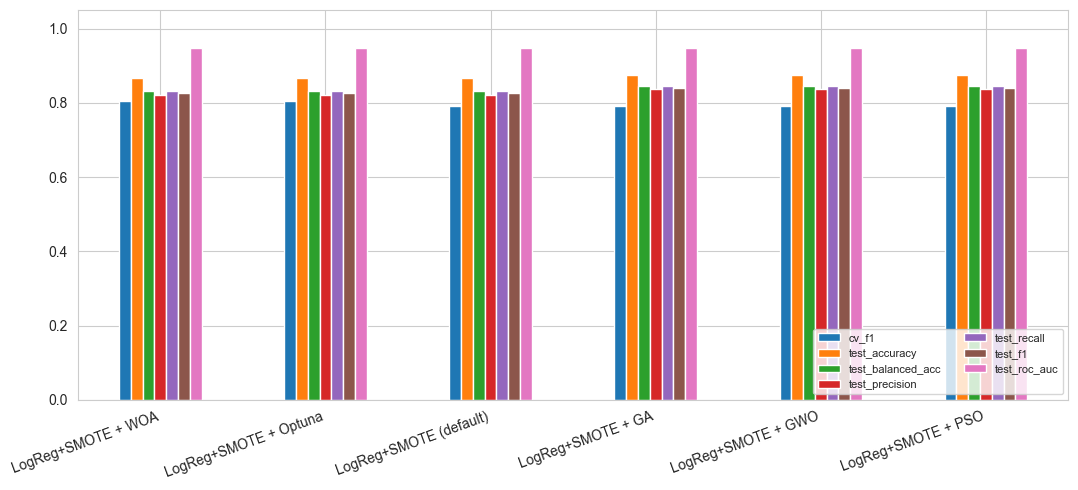

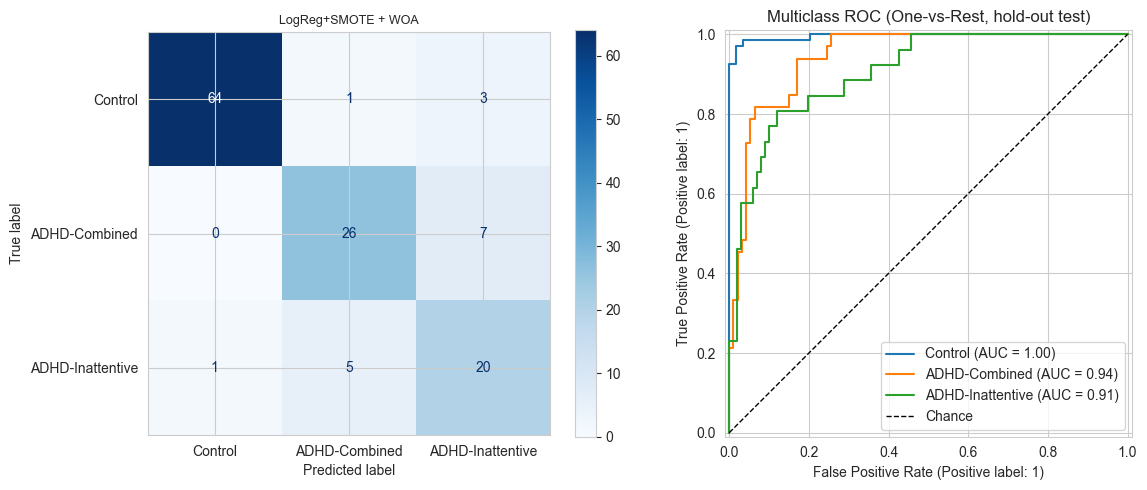

                  precision    recall  f1-score   support

         Control      0.985     0.941     0.962        68
   ADHD-Combined      0.812     0.788     0.800        33
ADHD-Inattentive      0.667     0.769     0.714        26

        accuracy                          0.866       127
       macro avg      0.821     0.833     0.826       127
    weighted avg      0.875     0.866     0.869       127



In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
final_df.plot.bar(ax=ax)
ax.set_ylim(0, 1.05); ax.legend(loc='lower right', fontsize=8, ncol=2)
plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(winner_pipe, X_test, y_test, labels=CLASSES,
                                      display_labels=CLASS_NAMES, cmap='Blues', ax=ax[0])
ax[0].set_title(winner_name, fontsize=9)

y_proba = winner_pipe.predict_proba(X_test)
for i, class_name in enumerate(CLASS_NAMES):
    RocCurveDisplay.from_predictions((y_test == CLASSES[i]).astype(int), y_proba[:, i],
                                     name=class_name, ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax[1].legend(loc='lower right'); ax[1].set_title('Multiclass ROC (One-vs-Rest, hold-out test)')
plt.tight_layout(); plt.show()

print(classification_report(y_test, winner_pipe.predict(X_test), target_names=CLASS_NAMES, digits=3))

## 8. Save final model

In [13]:
winner_params = next((r['params'] for r in tuning if winner_name.endswith(f"+ {r['optimizer']}")), {})
joblib.dump({'pipeline': winner_pipe, 'name': winner_name, 'model': BEST_MODEL, 'balancer': BEST_BALANCER,
             'params': winner_params, 'features': FEATURES, 'classes': CLASSES, 'class_names': CLASS_NAMES,
             'metrics': final_df.loc[winner_name].to_dict()},
            MODEL_DIR / 'best_tuned_model_multiclass.joblib')

bundle = joblib.load(MODEL_DIR / 'best_tuned_model_multiclass.joblib')
bundle['pipeline'].predict_proba(X_test[bundle['features']].head(5)).round(3)

array([[0.985, 0.001, 0.013],
       [0.031, 0.115, 0.854],
       [0.825, 0.142, 0.033],
       [0.978, 0.003, 0.019],
       [0.739, 0.023, 0.237]])

## 9. SHAP — which features push the model toward each class

Model-agnostic permutation explainer on the full pipeline, so values are in raw feature units and in predicted-probability space. There is one output per class: for class *k*, a positive SHAP value pushes the prediction toward class *k*, a negative one away from it.

In [14]:
test_pred = winner_pipe.predict(X_test)

background = shap.sample(X_train, 100, random_state=SEED)
explainer = shap.Explainer(
    lambda a: winner_pipe.predict_proba(pd.DataFrame(a, columns=FEATURES)),
    shap.maskers.Independent(background),
    algorithm='permutation', feature_names=FEATURES, output_names=CLASS_NAMES, seed=SEED)
shap_values = explainer(X_test)
shap_values.values.shape

PermutationExplainer explainer: 128it [00:10,  1.33it/s]                         


(127, 11, 3)

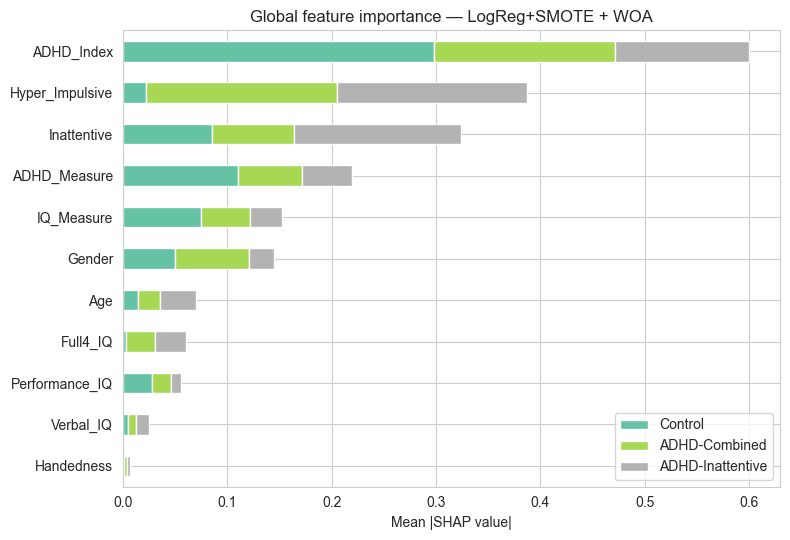

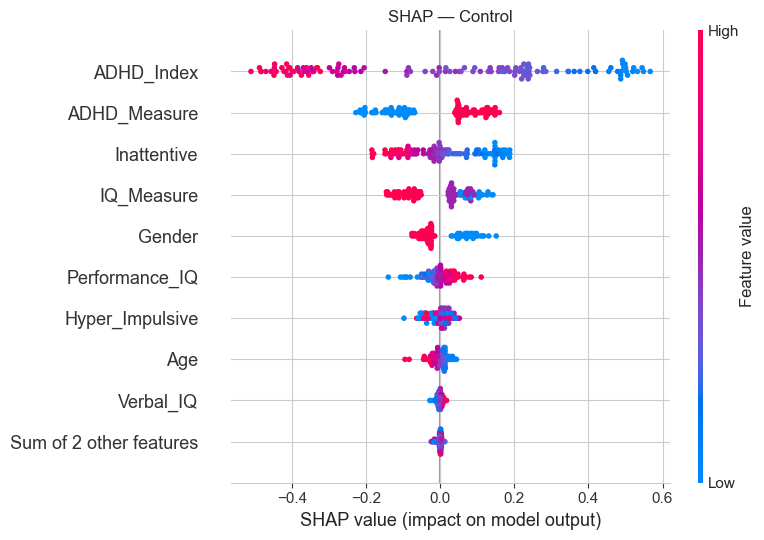

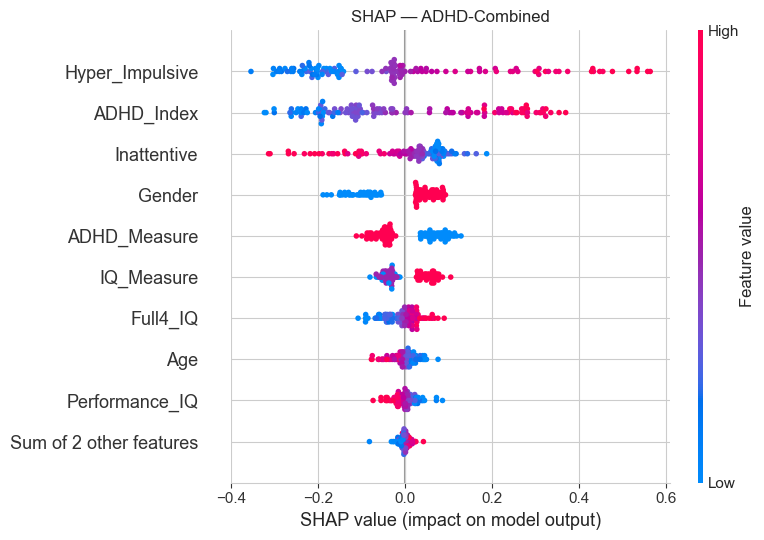

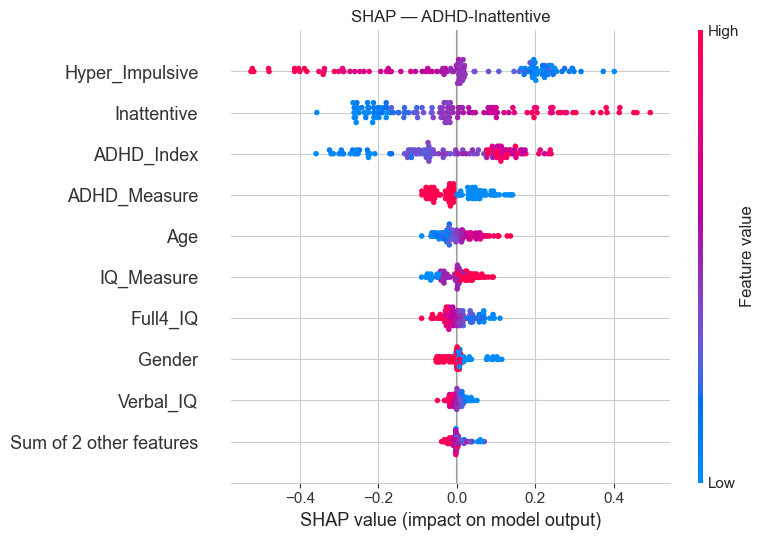

In [15]:
importance = pd.DataFrame(np.abs(shap_values.values).mean(axis=0), index=FEATURES, columns=CLASS_NAMES)
importance = importance.loc[importance.sum(axis=1).sort_values().index]

ax = importance.plot.barh(stacked=True, figsize=(8, 5.5), colormap='Set2')
ax.set_xlabel('Mean |SHAP value|'); ax.set_title(f'Global feature importance — {winner_name}')
plt.tight_layout(); plt.show()

for k, class_name in enumerate(CLASS_NAMES):
    shap.plots.beeswarm(shap_values[:, :, k], show=False)
    plt.title(f'SHAP — {class_name}')
    plt.tight_layout(); plt.show()

Test row 295 | true: Control | predicted: Control


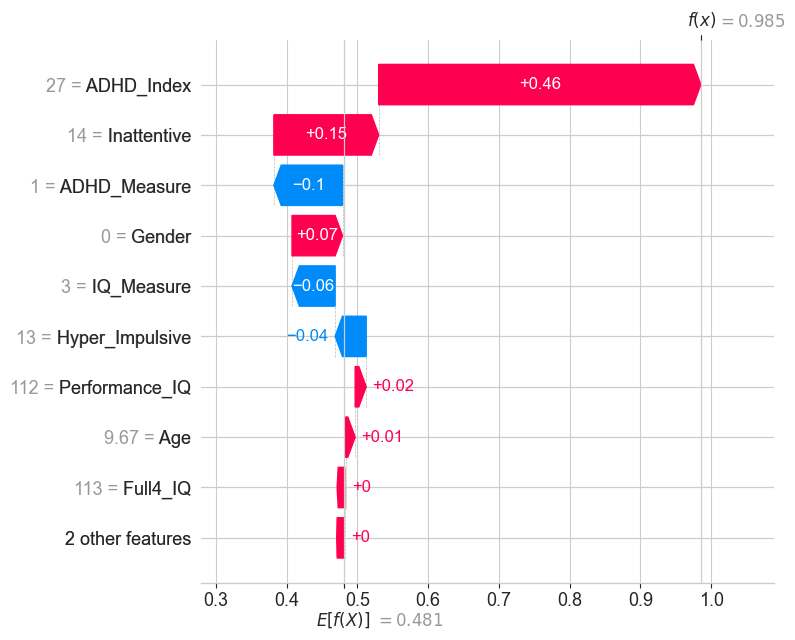

In [16]:
SAMPLE = 0
k = int(test_pred[SAMPLE])
print(f'Test row {X_test.index[SAMPLE]} | true: {CLASS_NAMES[y_test.iloc[SAMPLE]]} | predicted: {CLASS_NAMES[k]}')
shap.plots.waterfall(shap_values[SAMPLE, :, k], show=False)
plt.tight_layout(); plt.show()

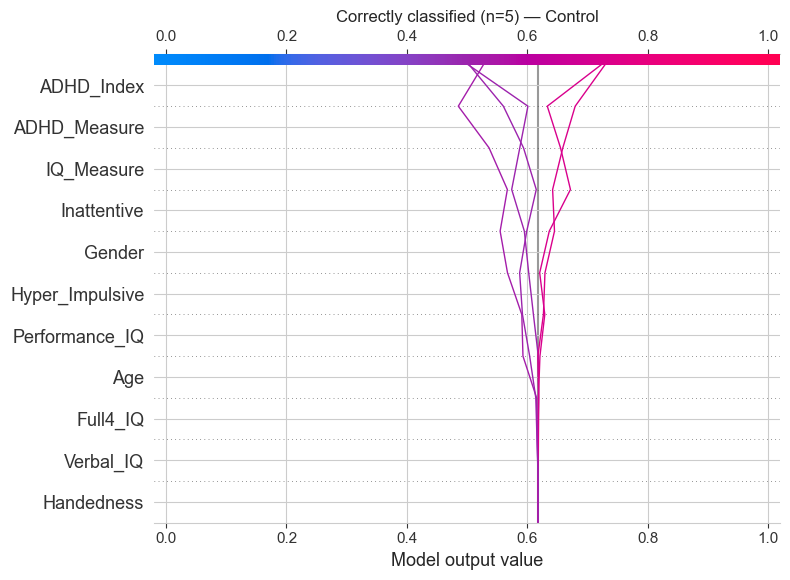

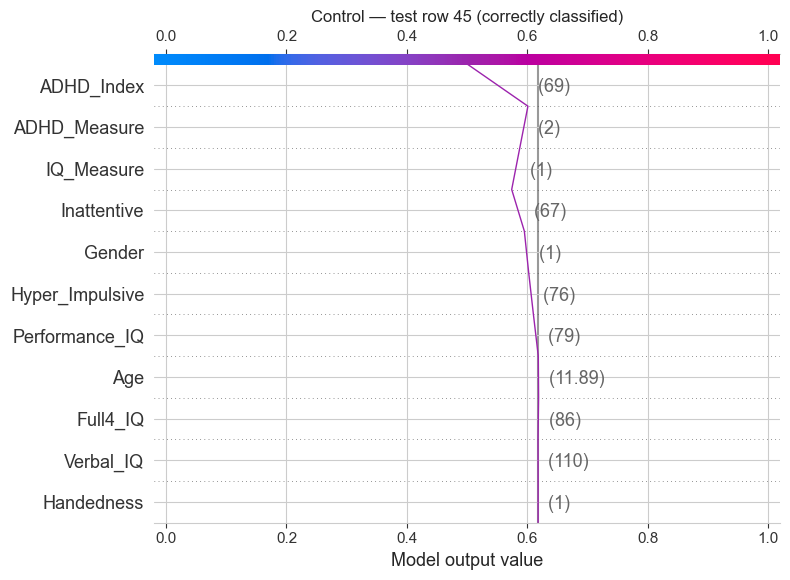

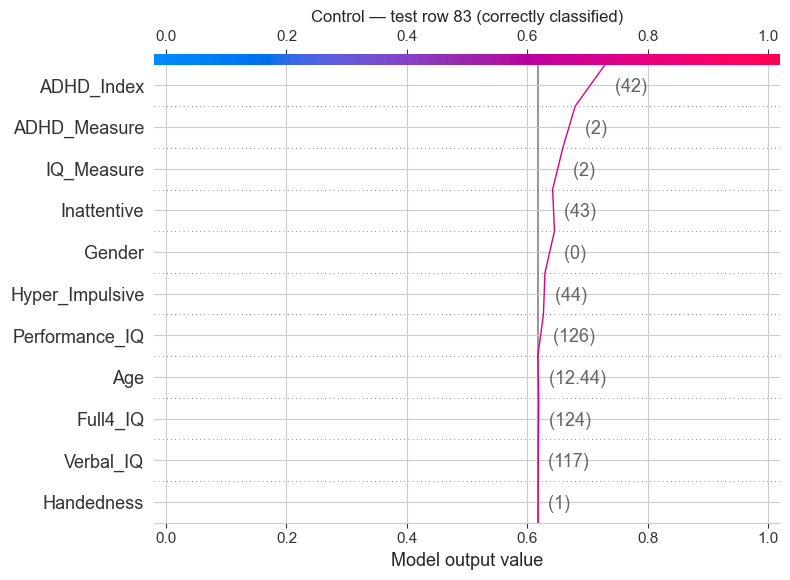

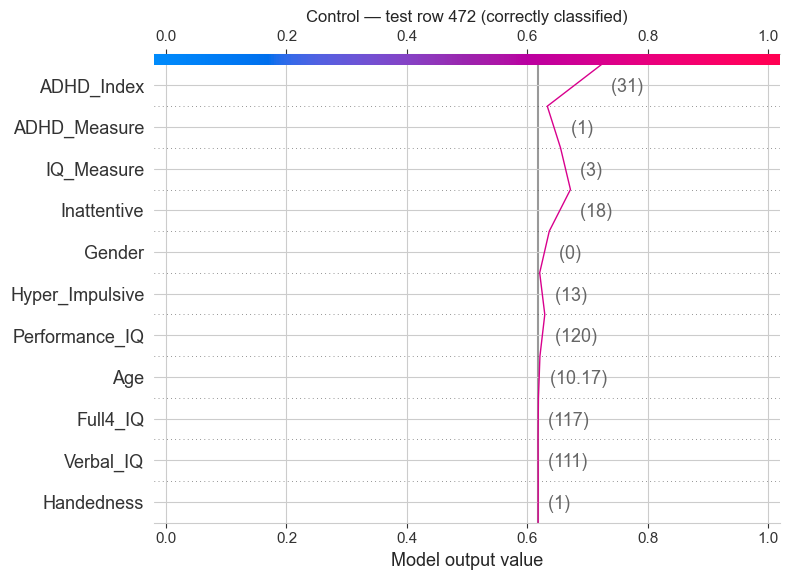

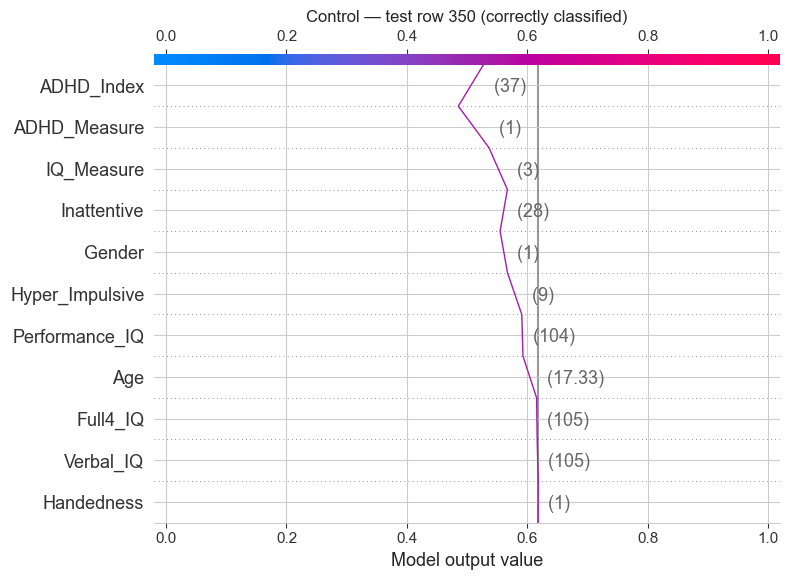

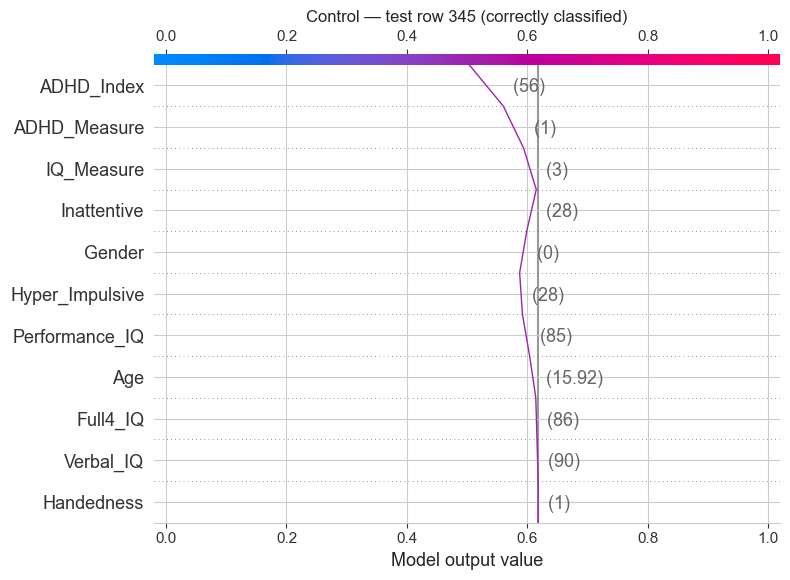

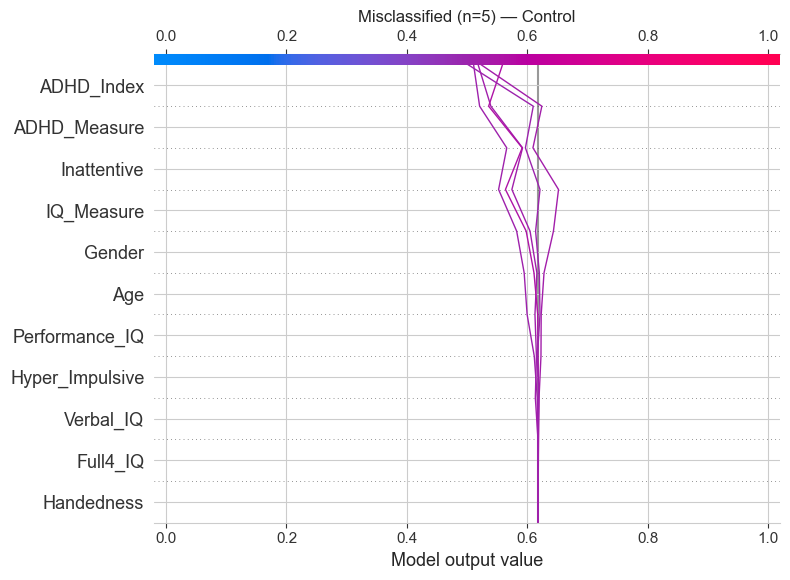

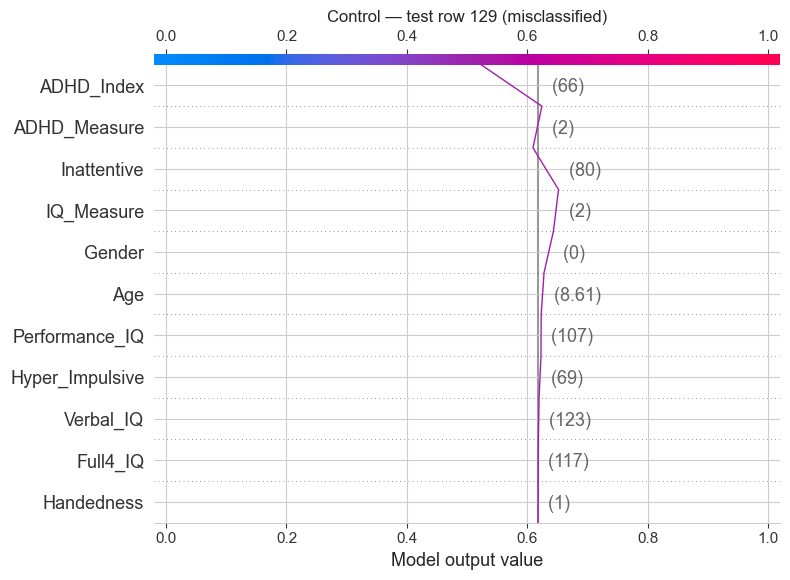

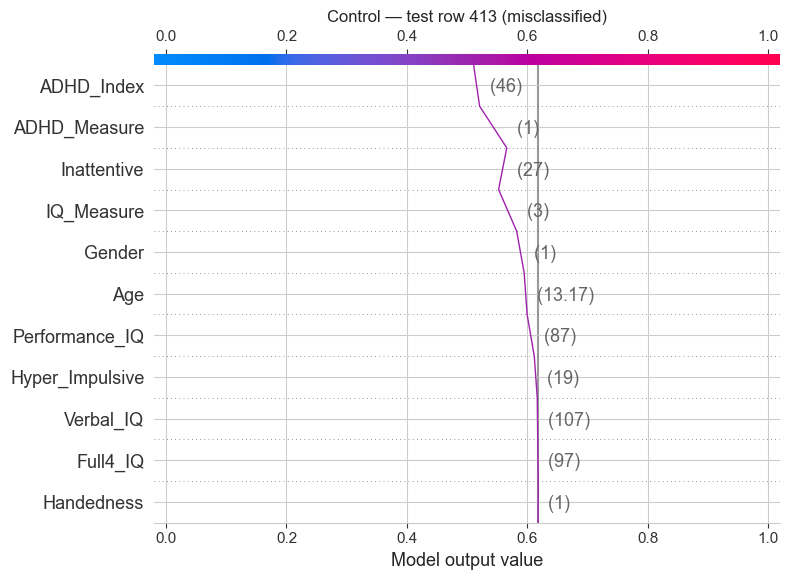

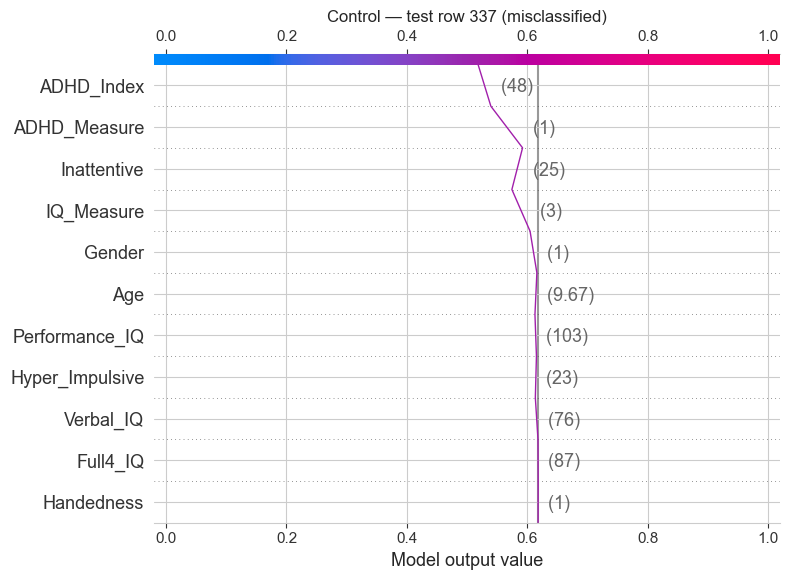

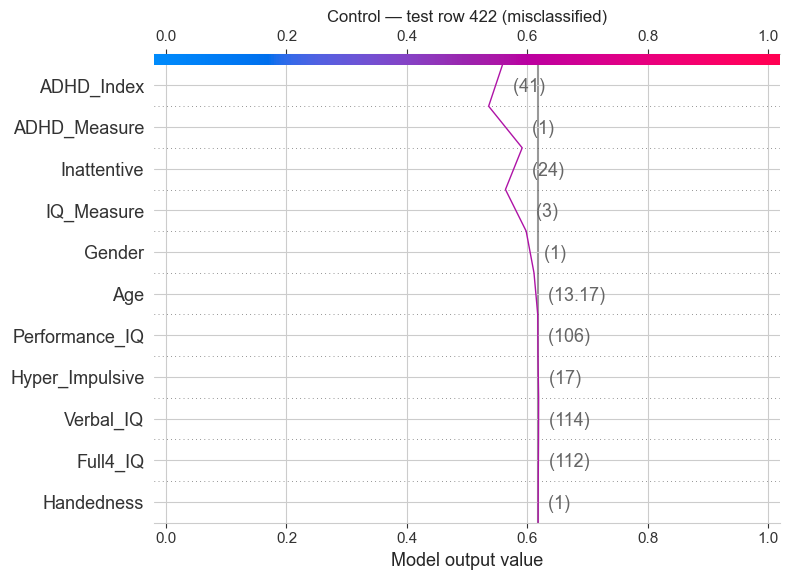

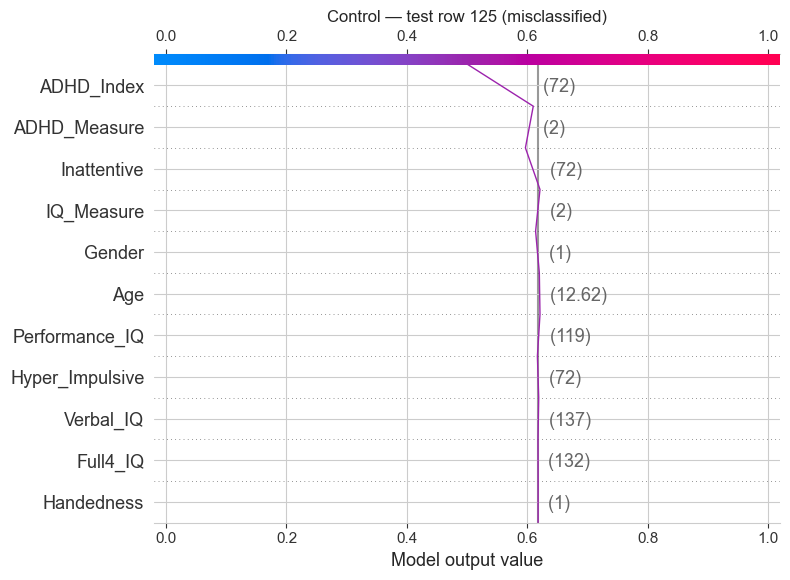

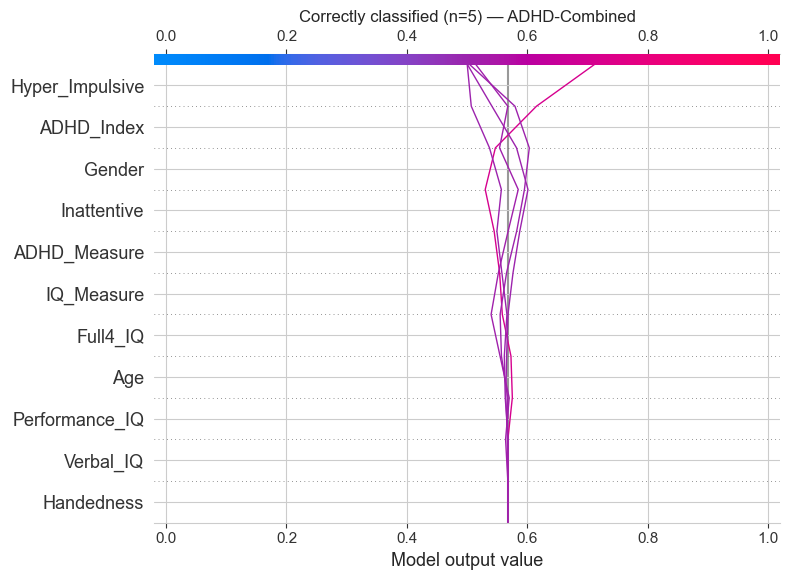

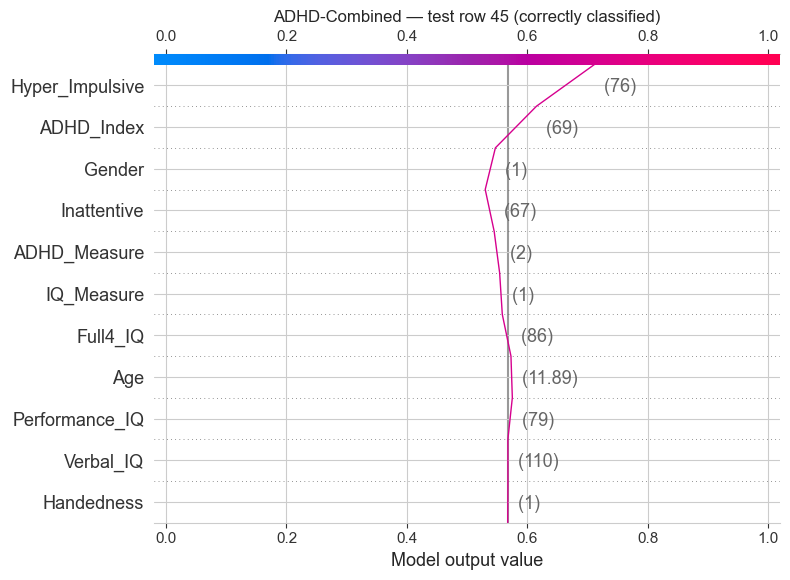

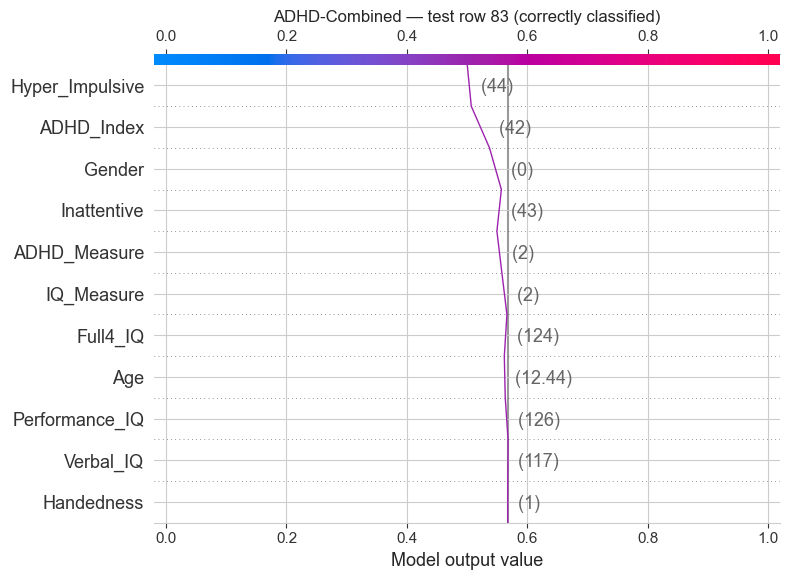

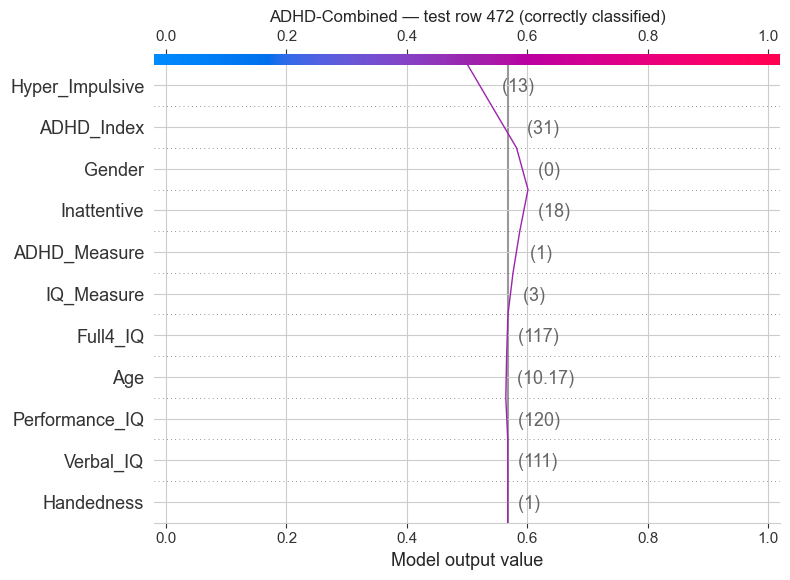

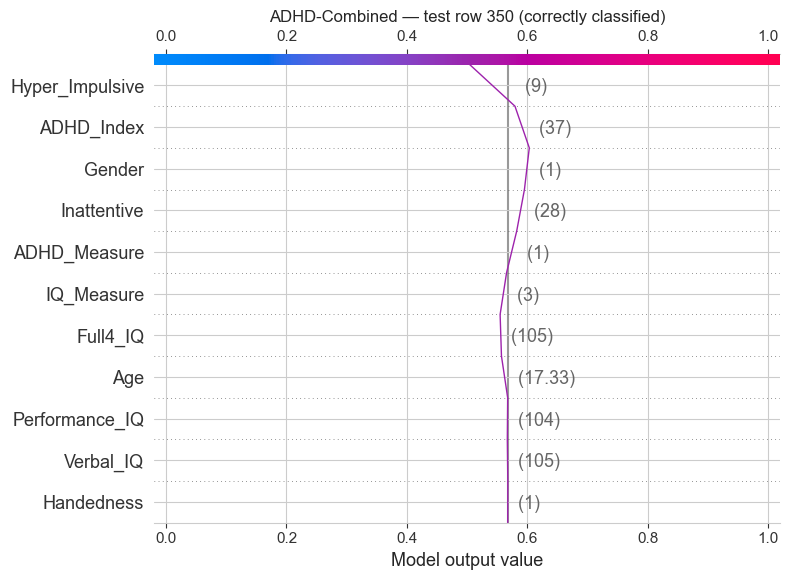

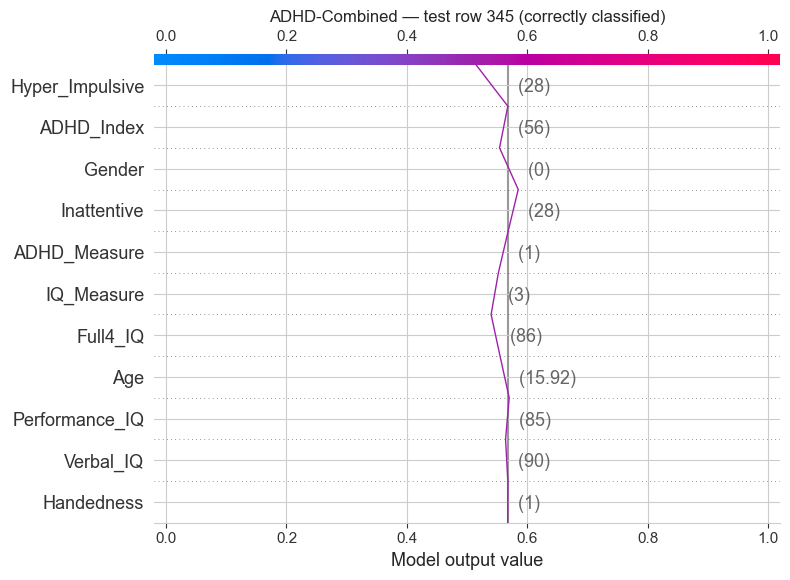

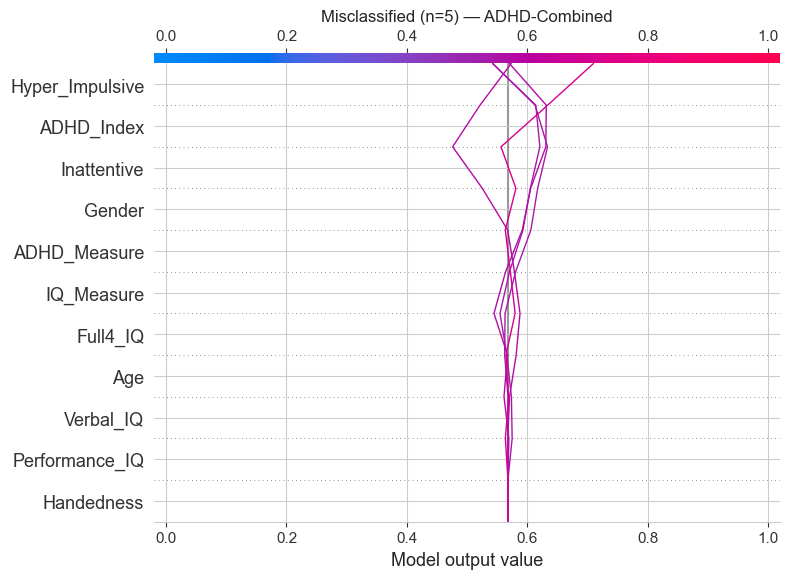

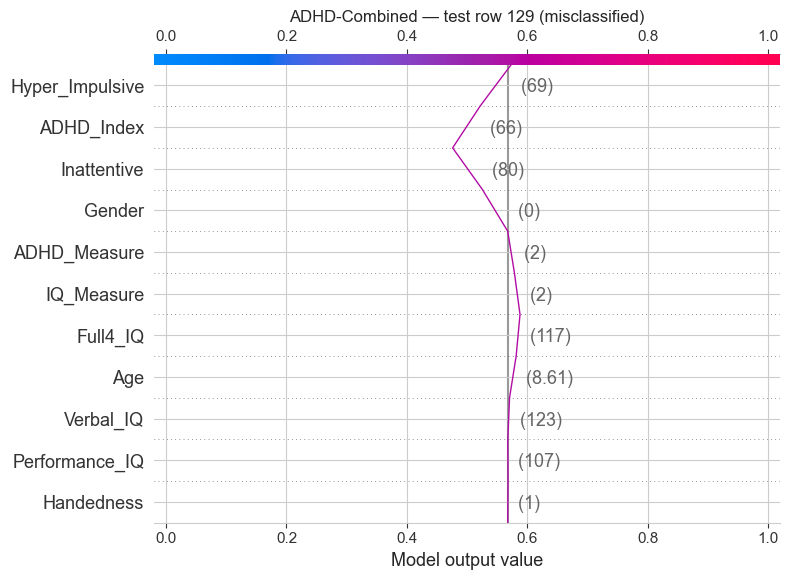

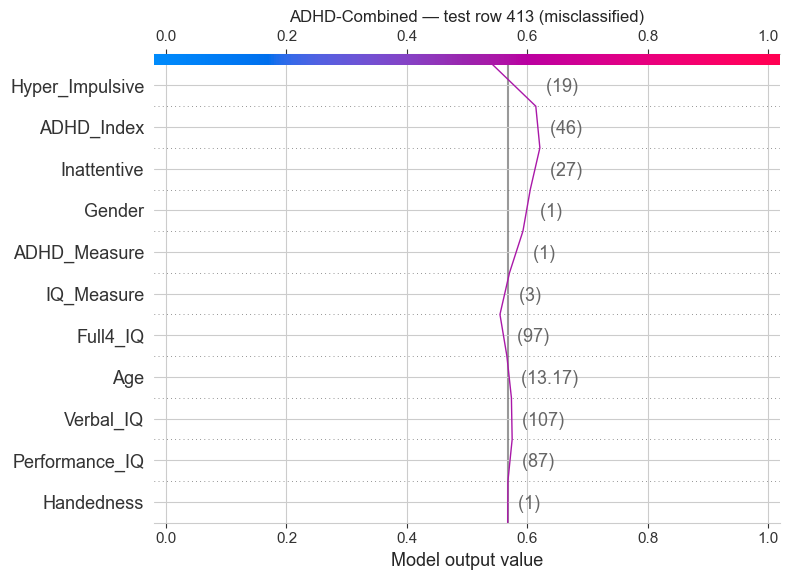

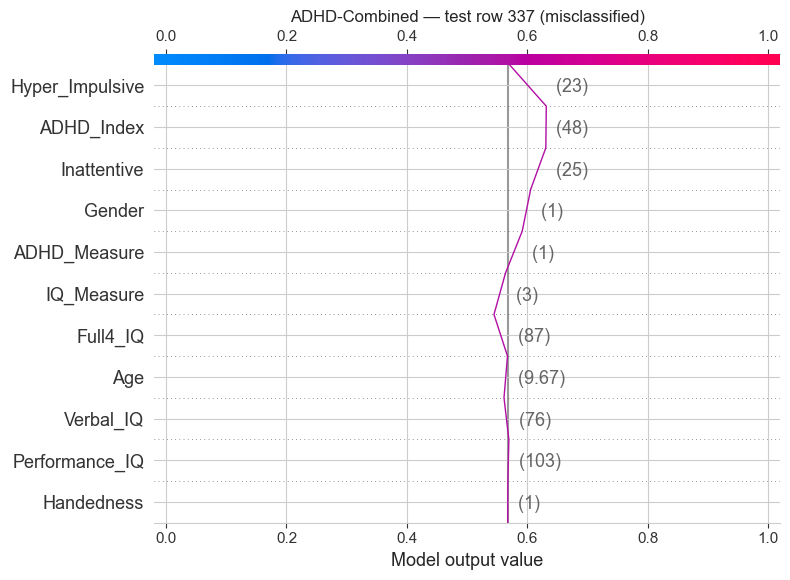

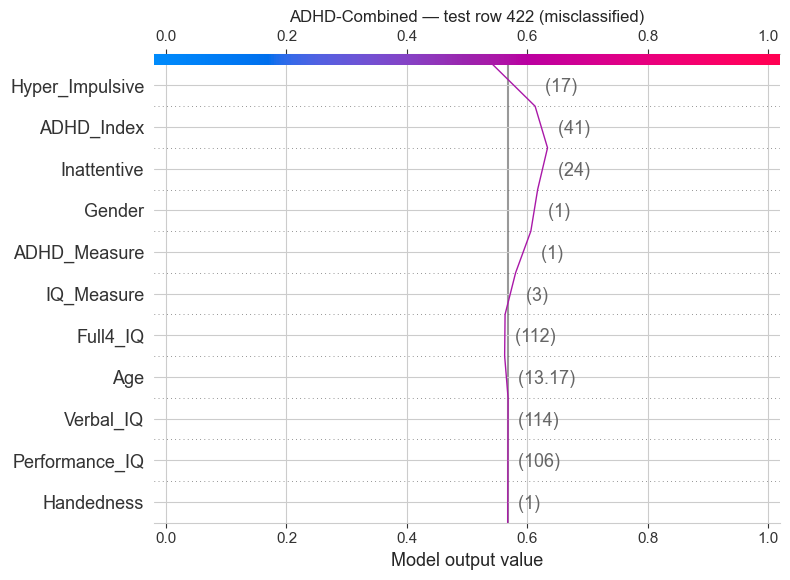

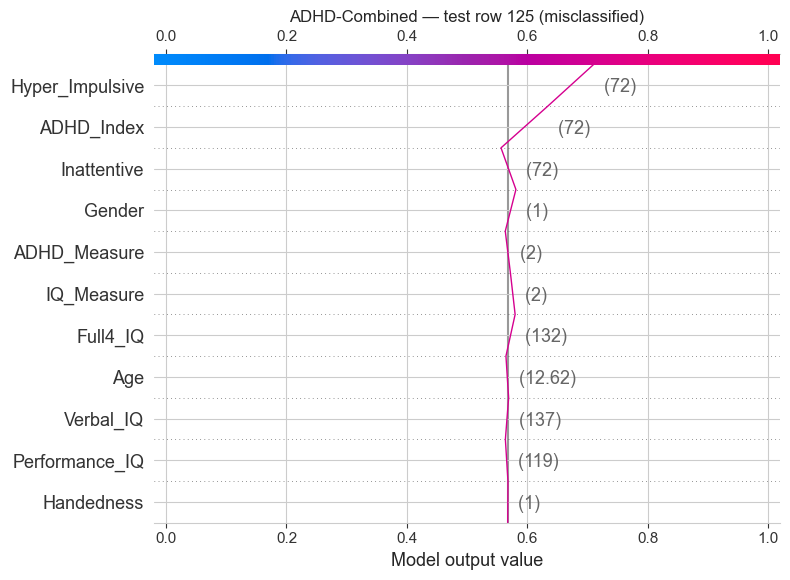

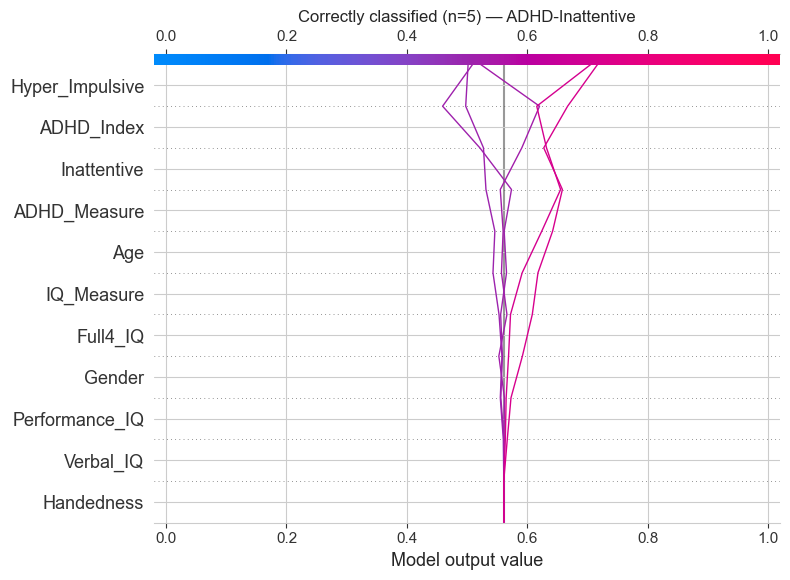

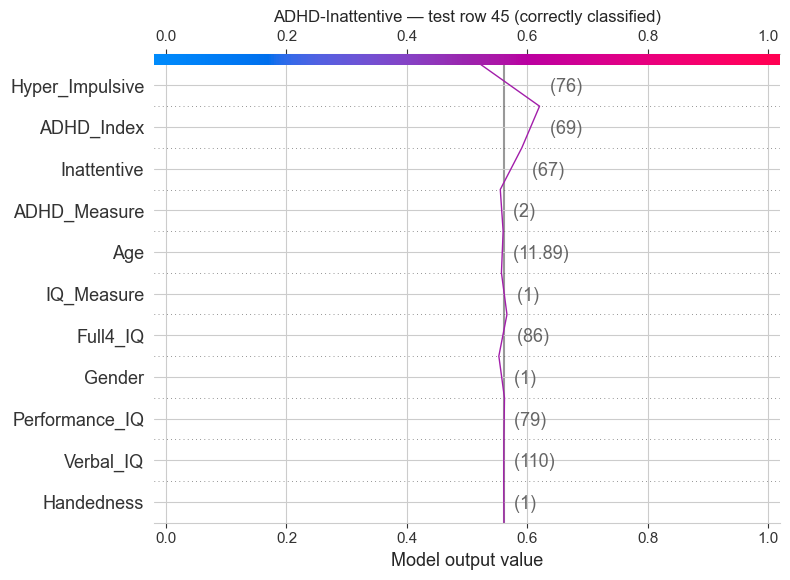

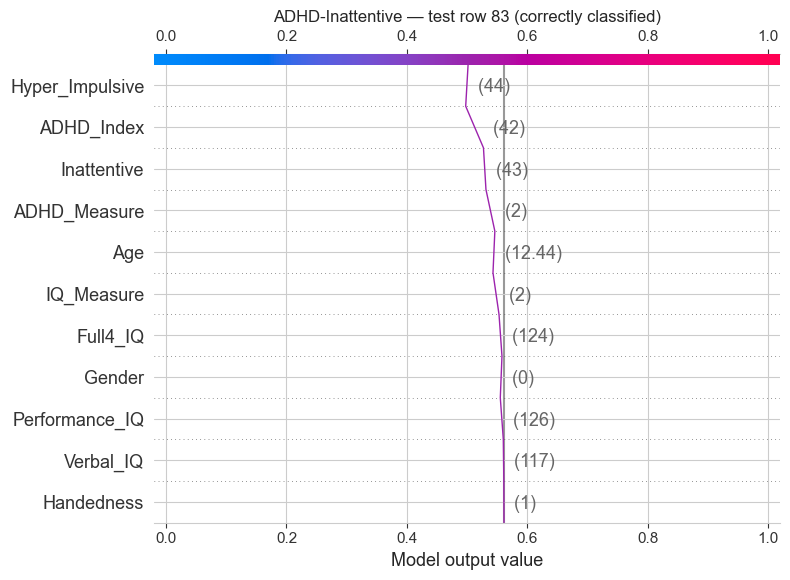

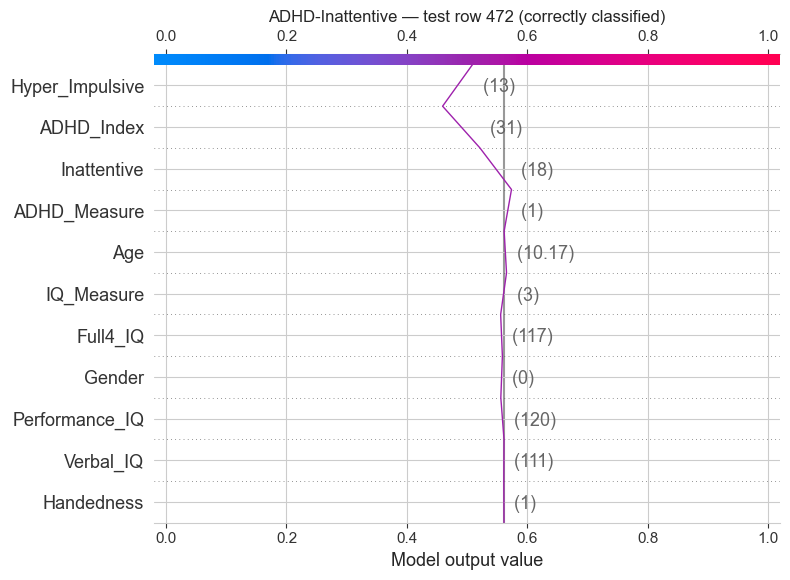

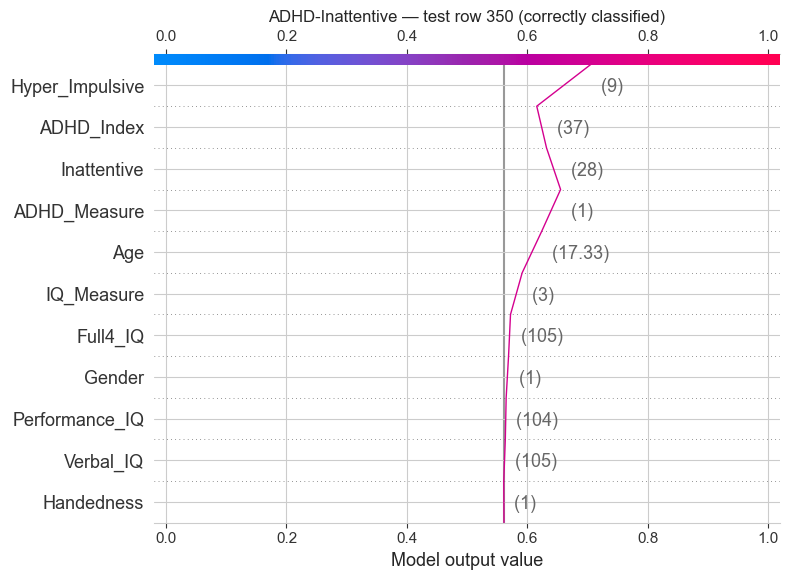

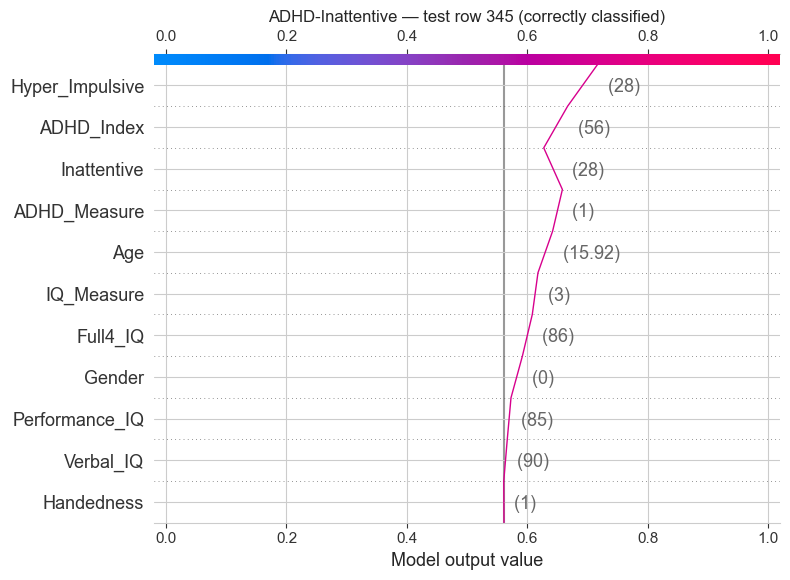

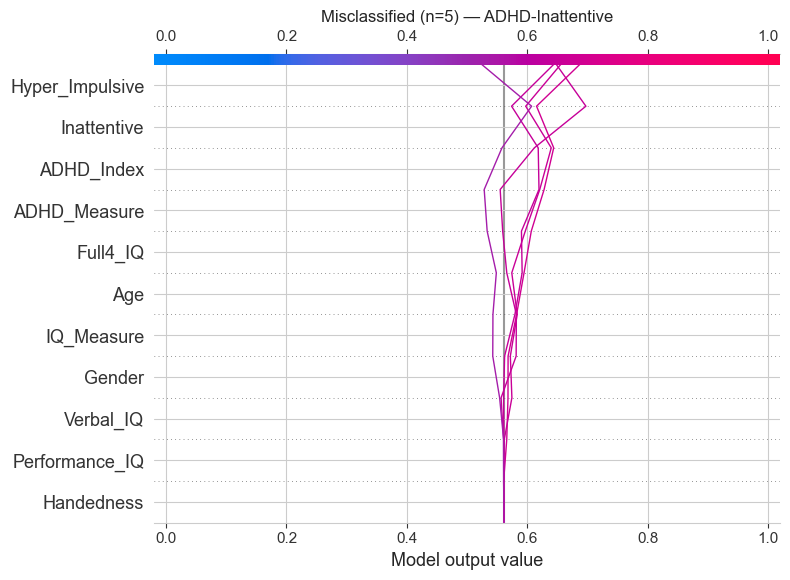

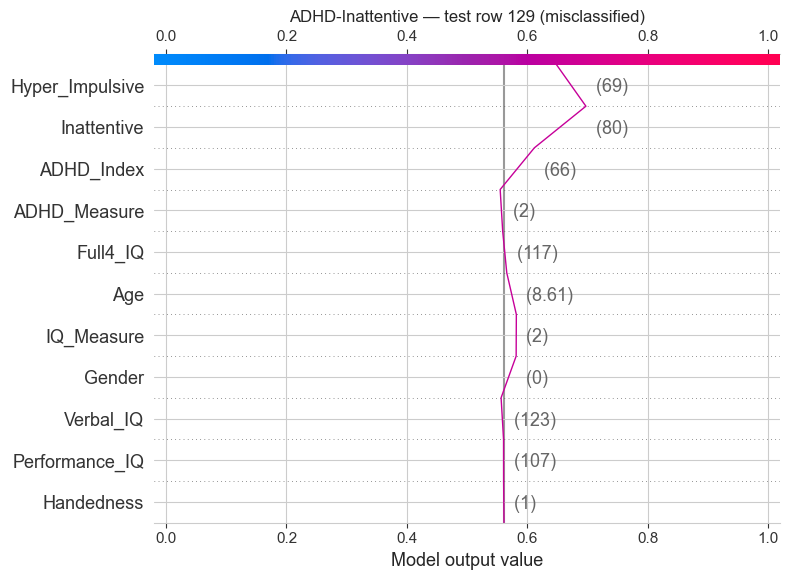

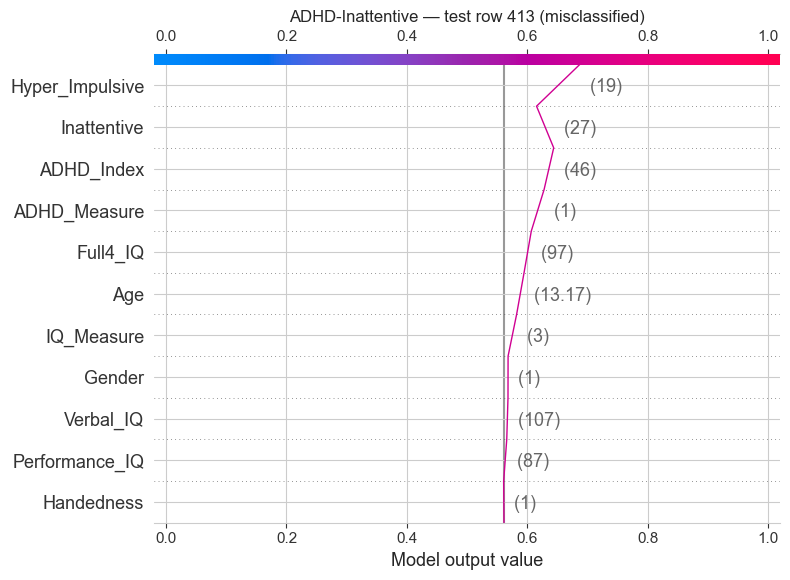

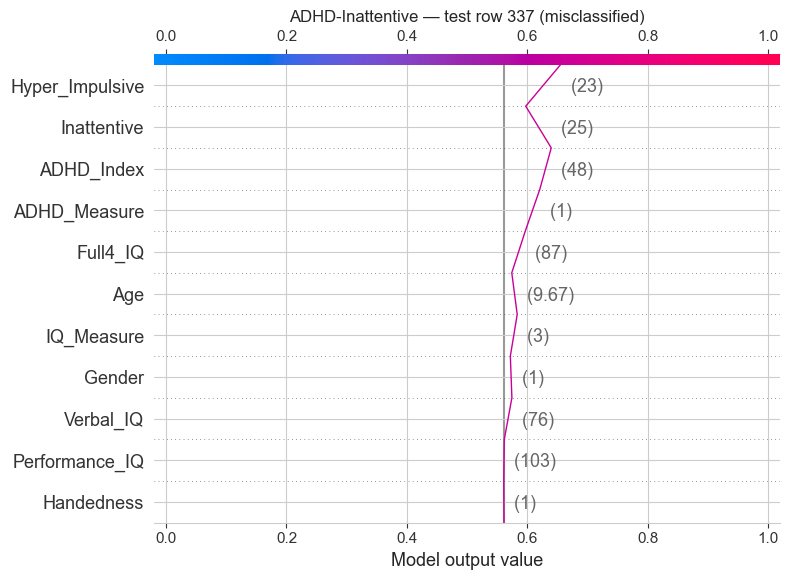

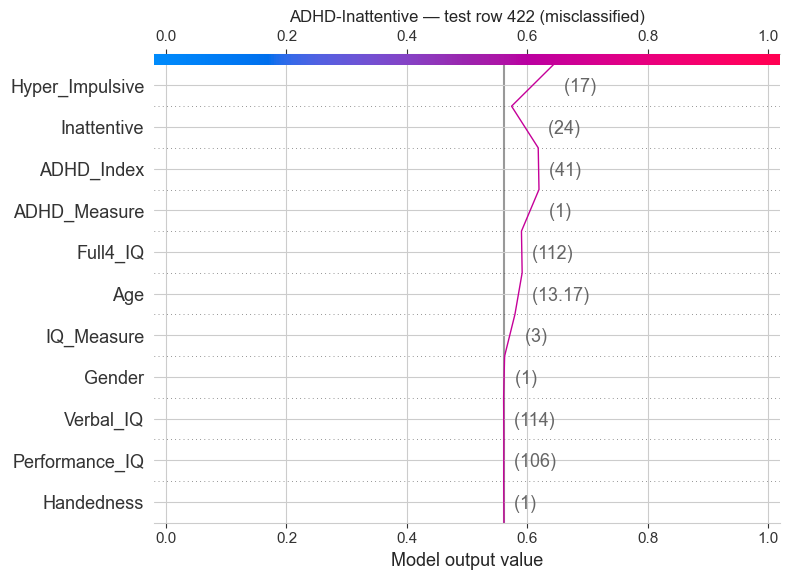

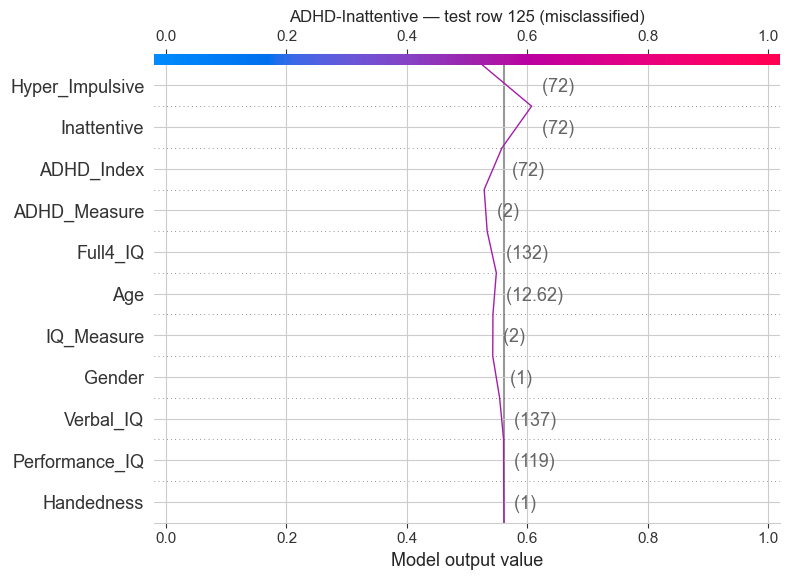

In [17]:
rng = np.random.default_rng(SEED)
correct = np.flatnonzero(test_pred == y_test.to_numpy())
mis = np.flatnonzero(test_pred != y_test.to_numpy())

correct5 = rng.choice(correct, size=min(5, len(correct)), replace=False)
mis5 = mis[:5]

for k, class_name in enumerate(CLASS_NAMES):
    expected_value = shap_values.base_values[0, k]
    sv = shap_values.values[:, :, k]

    for group_name, idxs in [('Correctly classified', correct5), ('Misclassified', mis5)]:
        if len(idxs) == 0:
            continue
        r = shap.decision_plot(expected_value, sv[idxs], X_test.iloc[idxs],
                               link='logit', return_objects=True, show=False)
        plt.title(f'{group_name} (n={len(idxs)}) — {class_name}')
        plt.tight_layout(); plt.show()

        for idx in idxs:
            shap.decision_plot(expected_value, sv[idx], X_test.iloc[idx],
                               link='logit', feature_order=r.feature_idx, xlim=r.xlim, show=False)
            plt.title(f'{class_name} — test row {X_test.index[idx]} ({group_name.lower()})')
            plt.tight_layout(); plt.show()

## 10. DiCE — diverse counterfactual explanations

For a subject predicted as one class: what feature changes would make the model predict a different class? Only the clinical scores and IQ values may change; gender, age, handedness and test types stay fixed.

In [18]:
CF_VARY = [c for c in ['ADHD_Index', 'Inattentive', 'Hyper_Impulsive', 'Verbal_IQ', 'Performance_IQ', 'Full4_IQ']
           if c in FEATURES]

dice = dice_ml.Dice(
    dice_ml.Data(dataframe=X_train.assign(**{TARGET: y_train}), continuous_features=NUM, outcome_name=TARGET),
    dice_ml.Model(model=winner_pipe, backend='sklearn'),
    method='random')


def counterfactuals(source, target, n=4):
    rows_src = np.flatnonzero(test_pred == source)
    if len(rows_src) == 0:
        return None
    query = X_test.iloc[[int(rows_src[0])]]
    cfs = dice.generate_counterfactuals(query, total_CFs=n, desired_class=target, features_to_vary=CF_VARY,
                                        random_seed=SEED).cf_examples_list[0].final_cfs_df[FEATURES]
    changed = [c for c in FEATURES if (cfs[c] != query.iloc[0][c]).any()]
    table = pd.concat([query[changed], cfs[changed]])
    table['predicted'] = [CLASS_NAMES[int(c)] for c in winner_pipe.predict(pd.concat([query, cfs])[FEATURES])]
    table.index = ['original'] + [f'cf {i + 1}' for i in range(len(cfs))]
    return table.round(1)


for source in CLASSES:
    for target in CLASSES:
        if source == target:
            continue
        print(f'\n{CLASS_NAMES[source]} -> {CLASS_NAMES[target]}')
        try:
            result = counterfactuals(source, target)
        except Exception as err:                       # DiCE raises when it finds no valid counterfactual
            print('  no counterfactual generated:', type(err).__name__)
            continue
        if result is None:
            print('  no test subject predicted as this class')
        else:
            display(result)


Control -> ADHD-Combined


100%|██████████| 1/1 [00:00<00:00, 13.08it/s]


,ADHD_Index,Hyper_Impulsive,predicted
original,27.0,13.0,Control
cf 1,50.7,45.8,ADHD-Combined
cf 2,56.7,52.5,ADHD-Combined
cf 3,66.5,63.5,ADHD-Combined
cf 4,89.1,88.9,ADHD-Combined



Control -> ADHD-Inattentive


100%|██████████| 1/1 [00:00<00:00, 13.06it/s]


,ADHD_Index,Inattentive,Performance_IQ,predicted
original,27.0,14.0,112.0,Control
cf 1,55.1,50.7,112.0,ADHD-Inattentive
cf 2,79.5,14.0,129.2,ADHD-Inattentive
cf 3,87.4,87.1,112.0,ADHD-Inattentive
cf 4,50.5,14.0,112.0,ADHD-Inattentive


... (8 outputs left out)

,ADHD_Index,Inattentive,Hyper_Impulsive,predicted
original,48.0,31.0,17.0,ADHD-Inattentive
cf 1,22.6,31.0,17.0,Control
cf 2,22.6,31.0,14.2,Control
cf 3,26.2,18.2,17.0,Control
cf 4,29.6,22.0,17.0,Control



ADHD-Inattentive -> ADHD-Combined


100%|██████████| 1/1 [00:00<00:00, 14.99it/s]


,Inattentive,Hyper_Impulsive,Verbal_IQ,predicted
original,31.0,17.0,112.0,ADHD-Inattentive
cf 1,31.0,52.7,112.0,ADHD-Combined
cf 2,52.6,52.6,112.0,ADHD-Combined
cf 3,31.0,35.3,95.1,ADHD-Combined
cf 4,31.0,31.1,112.0,ADHD-Combined
